# Sprint 4 Project: E-Commerce Customer Behavior EDA

Welcome to your Sprint 4 final project. In this project, you will apply everything you've learned across Sprints 1–4 to perform a complete Exploratory Data Analysis on the **Olist Brazilian E-Commerce dataset** — real data from a real e-commerce platform.


## Dataset

You'll work with 7 CSV files from the Olist e-commerce dataset:

| File | Rows | Description |
|---|---|---|
| `olist_orders_dataset.csv` | 99,441 | Orders with timestamps and status |
| `olist_order_items_dataset.csv` | 112,650 | Items per order with price and freight |
| `olist_customers_dataset.csv` | 99,441 | Customer ID, city, state |
| `olist_products_dataset.csv` | 32,951 | Products with category and dimensions |
| `olist_order_reviews_dataset.csv` | 99,224 | Review scores (1–5 stars) |
| `olist_order_payments_dataset.csv` | 103,886 | Payment type and value |
| `product_category_name_translation.csv` | 71 | Portuguese → English category names |

Let's get started!

---

## Setup

Run the cells below to import the libraries you'll need and load the datasets. The data is hosted on GitHub, so you can load it with one line of code per file — no uploads required.

In [1]:
# Import libraries
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Confirm versions
print(f"pandas version: {pd.__version__}")
print("Setup complete!")

pandas version: 3.1.1
Setup complete!


In [2]:
# Load the 7 datasets from the curriculum GitHub repo
BASE_URL = 'https://practicum-content.s3.us-west-1.amazonaws.com/data-analytics/eda-project/'

orders = pd.read_csv(BASE_URL + 'olist_orders_dataset.csv')
items = pd.read_csv(BASE_URL + 'olist_order_items_dataset.csv')
customers = pd.read_csv(BASE_URL + 'olist_customers_dataset.csv')
products = pd.read_csv(BASE_URL + 'olist_products_dataset.csv')
reviews = pd.read_csv(BASE_URL + 'olist_order_reviews_dataset.csv')
payments = pd.read_csv(BASE_URL + 'olist_order_payments_dataset.csv')
translation = pd.read_csv(BASE_URL + 'product_category_name_translation.csv')

print(f"orders:      {orders.shape}")
print(f"items:       {items.shape}")
print(f"customers:   {customers.shape}")
print(f"products:    {products.shape}")
print(f"reviews:     {reviews.shape}")
print(f"payments:    {payments.shape}")
print(f"translation: {translation.shape}")

orders:      (99441, 8)
items:       (112650, 7)
customers:   (99441, 5)
products:    (32951, 9)
reviews:     (99224, 7)
payments:    (103886, 5)
translation: (71, 2)


In [3]:
# Set up an in-memory SQLite database with all 7 tables
# This lets you run SQL queries directly against the DataFrames
conn = sqlite3.connect(':memory:')

orders.to_sql('orders', conn, index=False, if_exists='replace')
items.to_sql('items', conn, index=False, if_exists='replace')
customers.to_sql('customers', conn, index=False, if_exists='replace')
products.to_sql('products', conn, index=False, if_exists='replace')
reviews.to_sql('reviews', conn, index=False, if_exists='replace')
payments.to_sql('payments', conn, index=False, if_exists='replace')
translation.to_sql('translation', conn, index=False, if_exists='replace')

print("SQLite database ready. You can now run SQL queries with pd.read_sql().")

SQLite database ready. You can now run SQL queries with pd.read_sql().


---

## Question 1: Inspect the orders DataFrame

**Your task:** For the `orders` DataFrame:
1. Print its shape
2. Print the first 5 rows with `.head()`
3. Print column info with `.info()`

This is the very first thing every analyst does with a new dataset.

*Skills: Sprint 4 Ch 01 (Pandas inspection)*

In [4]:
# Your code here
# 1. Shape
print(orders.shape)

# 2. First 5 rows
print(orders.head())

# 3. Column info
orders.info()

# Extra: summary statistics for the text columns
print(orders.describe())

(99441, 8)
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00       

**Findings:** `orders` has **99,441 rows and 8 columns**, one row per order (all 99,441 `order_id`s are unique). All 8 columns are loaded as text, including the 5 date columns, so they need to be converted to datetime before any time analysis. `order_approved_at`, `order_delivered_carrier_date` and `order_delivered_customer_date` have fewer non-null values than the other columns, so some data is missing. 96,478 orders have the status `delivered`.

---

## Question 2: Clean the orders data

The `orders` DataFrame has timestamp columns stored as strings, and a few have missing values.

**Your task:**
1. Use `.isnull().sum()` to count missing values in each column of `orders`
2. Convert `order_purchase_timestamp` and `order_delivered_customer_date` to datetime using `pd.to_datetime()`
3. Print the dtypes after conversion to verify

*Skills: Sprint 4 Ch 02 (Cleaning, dtype conversion)*

In [5]:
# Your code here
# 1. Missing values per column
print(orders.isnull().sum())

# Check for fully duplicated rows and duplicate order IDs
print(f"\nDuplicate rows: {orders.duplicated().sum()}")
print(f"Duplicate order_ids: {orders['order_id'].duplicated().sum()}")
orders = orders.drop_duplicates().reset_index(drop=True)

# 2. Convert timestamp columns to datetime
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])

# 3. Verify dtypes
print()
print(orders.dtypes)

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64



Duplicate rows: 0
Duplicate order_ids: 0

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                           str
order_delivered_carrier_date                str
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date               str
dtype: object


**Findings:** There are no duplicate rows or duplicate order IDs. Missing values only appear in the approval/delivery timestamps: 160 for `order_approved_at`, 1,783 for `order_delivered_carrier_date` and **2,965 for `order_delivered_customer_date`**. These gaps make sense, because orders that were canceled, unavailable or still in transit have no delivery date yet. Filling them in with a mode or median would make up deliveries that never happened, so I keep them as missing and filter them out in Q9 instead. The two key columns are now `datetime64`.

---

## Question 3: Order status breakdown (SQL)

**Your task:** Write a SQL query against the `orders` table that returns:
- `order_status`
- `num_orders` — count of orders with that status
- `pct` — percentage of total orders, rounded to 2 decimals

Sort by `num_orders` descending. Save the result to a DataFrame called `status_summary` and print it.

**Hint:** Use `pd.read_sql("...", conn)`. The percentage trick is `COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders)`.

*Skills: Sprint 2 (SQL aggregation), Sprint 4 Ch 03 (Descriptive stats)*

In [6]:
# Your code here
status_summary = pd.read_sql("""
    SELECT order_status,
           COUNT(*) AS num_orders,
           ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders), 2) AS pct
    FROM orders
    GROUP BY order_status
    ORDER BY num_orders DESC
""", conn)
print(status_summary)

  order_status  num_orders    pct
0    delivered       96478  97.02
1      shipped        1107   1.11
2     canceled         625   0.63
3  unavailable         609   0.61
4     invoiced         314   0.32
5   processing         301   0.30
6      created           5   0.01
7     approved           2   0.00


**Findings:** **97.02%** of orders (96,478) were delivered. Only 1.11% are still shipped, and just **0.63% were canceled** and 0.61% unavailable. Overall, the business completes almost all of its orders.

---

## Question 4: Top 10 highest-revenue orders (SQL JOIN)

Each order can have multiple items. Total order revenue = sum of `price + freight_value` across all its items.

**Your task:** Write a SQL query that JOINs `orders` and `items` to find the **10 highest-revenue orders**. Return:
- `order_id`
- `order_status`
- `total_revenue` — rounded to 2 decimals

Save the result to `top_orders` and print it.

*Skills: Sprint 2 (SQL JOIN, GROUP BY), Sprint 4 Ch 06 (combining tables)*

In [7]:
# Your code here
top_orders = pd.read_sql("""
    SELECT o.order_id,
           o.order_status,
           ROUND(SUM(i.price + i.freight_value), 2) AS total_revenue
    FROM orders AS o
    JOIN items AS i ON o.order_id = i.order_id
    GROUP BY o.order_id, o.order_status
    ORDER BY total_revenue DESC
    LIMIT 10
""", conn)
print(top_orders)

                           order_id order_status  total_revenue
0  03caa2c082116e1d31e67e9ae3700499    delivered       13664.08
1  736e1922ae60d0d6a89247b851902527    delivered        7274.88
2  0812eb902a67711a1cb742b3cdaa65ae    delivered        6929.31
3  fefacc66af859508bf1a7934eab1e97f    delivered        6922.21
4  f5136e38d1a14a4dbd87dff67da82701    delivered        6726.66
5  2cc9089445046817a7539d90805e6e5a    delivered        6081.54
6  a96610ab360d42a2e5335a3998b4718a    delivered        4950.34
7  b4c4b76c642808cbe472a32b86cddc95     canceled        4809.44
8  199af31afc78c699f0dbf71fb178d4d4    delivered        4764.34
9  8dbc85d1447242f3b127dda390d56e19    delivered        4681.78


**Findings:** The largest order brought in **13,664.08**, almost twice as much as the next one (7,274.88). The rest of the top 10 range from about 4,700 to 6,900. 9 of the top 10 orders were delivered, but one high-value order (4,809.44) was **canceled**, which is a large amount of lost revenue.

---

## Question 5: English product categories (pandas merge)

The `products` table has a Portuguese category column called `product_category_name`. The `translation` table maps each Portuguese name to its English equivalent.

**Your task:**
1. Use `products.merge(translation, on='product_category_name', how='left')` to add the English column. Save it to `products_eng`.
2. Find the **top 10 categories by number of products** using `value_counts()` on the `product_category_name_english` column. Save to `top_categories` and print it.

*Skills: Sprint 4 Ch 06 (pandas merge), Ch 03 (value_counts)*

In [8]:
# Your code here
products_eng = products.merge(translation, on='product_category_name', how='left')
top_categories = products_eng['product_category_name_english'].value_counts().head(10)
print(top_categories)

product_category_name_english
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
watches_gifts            1329
telephony                1134
Name: count, dtype: int64


**Findings:** The catalog is led by home and lifestyle products: **bed_bath_table (3,029 products)**, sports_leisure (2,867), furniture_decor (2,657), health_beauty (2,444) and housewares (2,335).

---

## Question 6: Revenue and average review score by category

Now you'll combine three tables and compute multiple metrics per category.

**Your task:**
1. Build a DataFrame that merges `items` with `products_eng` (to get categories), then merges with `reviews` (to get scores). The shared key chain is: `items.product_id → products_eng.product_id` and `items.order_id → reviews.order_id`.
2. Add a `revenue` column = `price + freight_value`
3. Group by `product_category_name_english` and aggregate:
   - `total_revenue` = sum of `revenue`
   - `avg_review` = mean of `review_score`
   - `n_items` = count of `order_id`
4. Sort by `total_revenue` descending and show the **top 10 categories**. Save to `category_summary`.

*Skills: Sprint 4 Ch 06 (multi-table merge, groupby with multiple aggregations)*

In [9]:
# Your code here
# 1. Merge items -> products_eng (category) -> reviews (score)
items_cat = items.merge(products_eng[['product_id', 'product_category_name_english']],
                        on='product_id', how='left')
items_cat_rev = items_cat.merge(reviews[['order_id', 'review_score']],
                                on='order_id', how='left')

# 2. Revenue per item
items_cat_rev['revenue'] = items_cat_rev['price'] + items_cat_rev['freight_value']

# 3. Aggregate by category
category_summary = (
    items_cat_rev.groupby('product_category_name_english')
    .agg(total_revenue=('revenue', 'sum'),
         avg_review=('review_score', 'mean'),
         n_items=('order_id', 'count'))
    # 4. Top 10 by revenue
    .sort_values('total_revenue', ascending=False)
    .head(10)
    .round(2)
)
print(category_summary)

# Context: share of all item revenue captured by these top 10 categories
total_item_revenue = items_cat_rev['revenue'].sum()
print(f"\nTotal item revenue (price + freight): {total_item_revenue:,.2f}")
print(f"Top 10 categories' share of revenue: {category_summary['total_revenue'].sum() / total_item_revenue * 100:.1f}%")
print(f"Overall average review score: {items_cat_rev['review_score'].mean():.2f}")

                               total_revenue  avg_review  n_items
product_category_name_english                                    
health_beauty                     1446622.08        4.14     9727
watches_gifts                     1306761.40        4.02     6001
bed_bath_table                    1258189.51        3.90    11270
sports_leisure                    1163329.98        4.11     8700
computers_accessories             1068070.48        3.93     7894
furniture_decor                    910683.05        3.90     8415
housewares                         781170.03        4.06     6989
cool_stuff                         721492.90        4.15     3806
auto                               687374.19        4.07     4256
garden_tools                       585646.54        4.04     4361

Total item revenue (price + freight): 15,915,872.32
Top 10 categories' share of revenue: 62.4%
Overall average review score: 4.03


**Findings:** **health_beauty** brings in the most revenue (**1,446,622.08**) with a strong 4.14 average review. It is followed by watches_gifts (1,306,761.40) and bed_bath_table (1,258,189.51). The top 10 categories make up **62.4%** of total item revenue. bed_bath_table sells the most items (11,270), but along with furniture_decor it has the lowest review score in the top 10 (3.90). cool_stuff (4.15), health_beauty (4.14) and sports_leisure (4.11) have the most satisfied customers.

---

## Question 7: Top 10 customer states (SQL + bar chart)

**Your task:**
1. Write a SQL query that returns the **top 10 customer states** by number of customers. Columns: `customer_state`, `num_customers`. Save to `state_top10`.
2. Create a **bar chart** of `num_customers` by `customer_state`. Add a title and rotate the x-tick labels if they overlap.

*Skills: Sprint 2 (SQL GROUP BY), Sprint 4 Ch 04 (bar chart)*

  customer_state  num_customers
0             SP          40302
1             RJ          12384
2             MG          11259
3             RS           5277
4             PR           4882
5             SC           3534
6             BA           3277
7             DF           2075
8             ES           1964
9             GO           1952

Total unique customers: 96096
SP share: 41.9%
Top 3 states (SP, RJ, MG) share: 66.5%


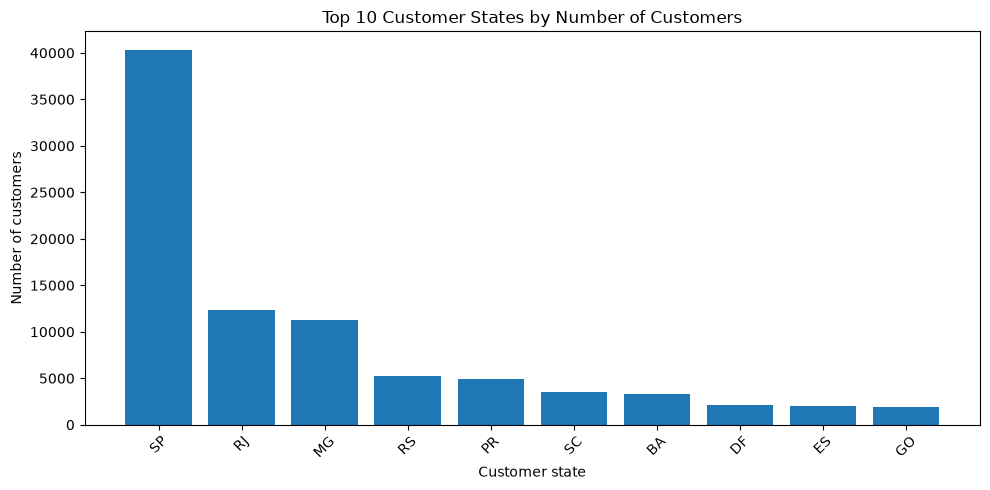

In [10]:
# Your code here
state_top10 = pd.read_sql("""
    SELECT customer_state,
           COUNT(DISTINCT customer_unique_id) AS num_customers
    FROM customers
    GROUP BY customer_state
    ORDER BY num_customers DESC
    LIMIT 10
""", conn)
print(state_top10)

# Context: share of all unique customers living in each of the top states
total_customers = customers['customer_unique_id'].nunique()
print(f"\nTotal unique customers: {total_customers}")
print(f"SP share: {state_top10.loc[0, 'num_customers'] / total_customers * 100:.1f}%")
print(f"Top 3 states (SP, RJ, MG) share: {state_top10['num_customers'].head(3).sum() / total_customers * 100:.1f}%")

plt.figure(figsize=(10, 5))
plt.bar(state_top10['customer_state'], state_top10['num_customers'])
plt.title('Top 10 Customer States by Number of Customers')
plt.xlabel('Customer state')
plt.ylabel('Number of customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Findings:** **SP (São Paulo)** has by far the most customers: **40,302 unique customers, 41.9%** of the total of 96,096. It is followed by RJ (12,384) and MG (11,259). Together these three southeastern states make up **66.5%** of all customers. I counted `customer_unique_id`, because `customer_id` is created again for each order, so counting it would count orders instead of people.

---

## Question 8: Monthly order trend (line chart)

**Your task:**
1. From the cleaned `orders` DataFrame (with datetime columns from Q2), extract a `year_month` period from `order_purchase_timestamp` using `.dt.to_period('M')`
2. Count orders per month — save to a DataFrame called `monthly_orders` with columns `year_month` and `num_orders`
3. Plot a **line chart** of `num_orders` over time. Add a title.

**Hint:** `orders['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()` is a fast way to get monthly counts. Convert the period index back to string for plotting.

*Skills: Sprint 4 Ch 02 (datetime), Ch 03 (groupby), Ch 04 (line chart)*

   year_month  num_orders
0     2016-09           4
1     2016-10         324
2     2016-12           1
3     2017-01         800
4     2017-02        1780
5     2017-03        2682
6     2017-04        2404
7     2017-05        3700
8     2017-06        3245
9     2017-07        4026
10    2017-08        4331
11    2017-09        4285
12    2017-10        4631
13    2017-11        7544
14    2017-12        5673
15    2018-01        7269
16    2018-02        6728
17    2018-03        7211
18    2018-04        6939
19    2018-05        6873
20    2018-06        6167
21    2018-07        6292
22    2018-08        6512
23    2018-09          16
24    2018-10           4

Orders Jan-Aug 2017: 22968
Orders Jan-Aug 2018: 53991
Growth: 135.1%


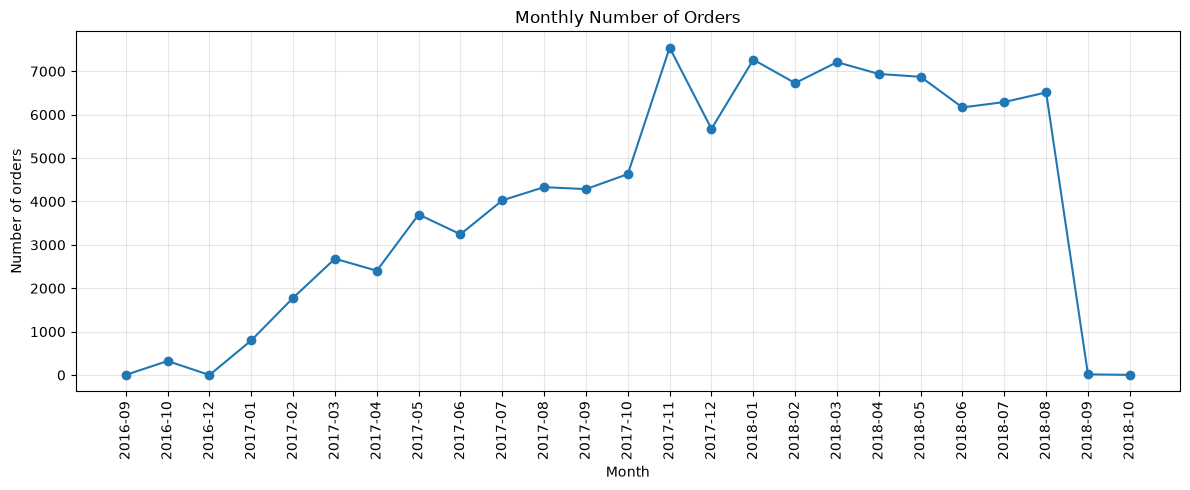

In [11]:
# Your code here
orders['year_month'] = orders['order_purchase_timestamp'].dt.to_period('M')
monthly_orders = orders['year_month'].value_counts().sort_index().reset_index()
monthly_orders.columns = ['year_month', 'num_orders']
monthly_orders['year_month'] = monthly_orders['year_month'].astype(str)
print(monthly_orders)

# Context: compare the same 8 months (Jan-Aug) in 2017 and 2018 (the data ends in early Sep/Oct 2018)
jan_aug_2017 = monthly_orders[monthly_orders['year_month'].between('2017-01', '2017-08')]['num_orders'].sum()
jan_aug_2018 = monthly_orders[monthly_orders['year_month'].between('2018-01', '2018-08')]['num_orders'].sum()
print(f"\nOrders Jan-Aug 2017: {jan_aug_2017}")
print(f"Orders Jan-Aug 2018: {jan_aug_2018}")
print(f"Growth: {(jan_aug_2018 / jan_aug_2017 - 1) * 100:.1f}%")

plt.figure(figsize=(12, 5))
plt.plot(monthly_orders['year_month'], monthly_orders['num_orders'], marker='o')
plt.title('Monthly Number of Orders')
plt.xlabel('Month')
plt.ylabel('Number of orders')
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Findings:** Orders grew steadily through 2017 and reached a peak of **7,544 in November 2017** (Black Friday season). In 2018 they stayed between about 6,200 and 7,300 a month. January–August 2018 had **53,991** orders, compared with 22,968 in the same months of 2017 (**+135.1%**). The very low numbers in 2016 and in September–October 2018 come from incomplete data at the start and end of the dataset, not from real drops in demand.

---

## Question 9: Does delivery speed affect review scores?

This is a real business question: do customers who get their orders faster leave better reviews?

**Your task:**
1. From `orders`, keep only rows where `order_delivered_customer_date` is not null
2. Add a `delivery_days` column = (delivery date − purchase date) in days. **Hint:** subtract the two datetime columns and use `.dt.days`
3. Merge with `reviews` on `order_id` to get the `review_score` for each order
4. Compute the **correlation** between `delivery_days` and `review_score` using `.corr()`
5. Group by `review_score` and show the **average delivery days** for each score (1 through 5)
6. Plot a bar chart of average delivery days by review score

What pattern do you see? Add a markdown cell with your interpretation.

*Skills: Sprint 4 Ch 03 (correlation), Ch 04 (visualization), Ch 06 (merge + groupby)*

       delivery_days  review_score
count   96359.000000  96359.000000
mean       12.058957      4.155554
std         9.463076      1.285108
min         0.000000      1.000000
25%         6.000000      4.000000
50%        10.000000      5.000000
75%        15.000000      5.000000
max       208.000000      5.000000

Correlation between delivery_days and review_score: -0.334

Average delivery days by review score:
review_score
1    20.85
2    16.19
3    13.80
4    11.85
5    10.22
Name: delivery_days, dtype: float64

Share of orders by review score (%):
review_score
1     9.8
2     3.1
3     8.3
4    19.7
5    59.2
Name: proportion, dtype: float64

1-2 star rate, delivered in <=10 days: 8.0% (52082 orders)
1-2 star rate, delivered in >20 days: 38.2% (12392 orders)


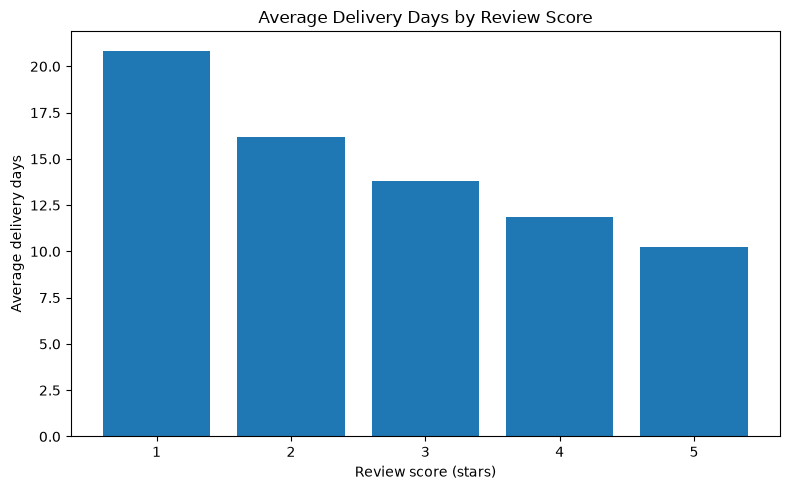

In [12]:
# Your code here
# 1. Keep only delivered orders
delivered = orders[orders['order_delivered_customer_date'].notnull()].copy()

# 2. Delivery time in days
delivered['delivery_days'] = (delivered['order_delivered_customer_date']
                              - delivered['order_purchase_timestamp']).dt.days

# 3. Merge with reviews
delivery_reviews = delivered.merge(reviews[['order_id', 'review_score']], on='order_id', how='inner')
print(delivery_reviews[['delivery_days', 'review_score']].describe())

# 4. Correlation
corr = delivery_reviews['delivery_days'].corr(delivery_reviews['review_score'])
print(f"\nCorrelation between delivery_days and review_score: {corr:.3f}")

# 5. Average delivery days by review score
avg_days_by_score = delivery_reviews.groupby('review_score')['delivery_days'].mean().round(2)
print("\nAverage delivery days by review score:")
print(avg_days_by_score)

# Share of each review score among delivered orders, and low-score rate for fast vs slow deliveries
print("\nShare of orders by review score (%):")
print((delivery_reviews['review_score'].value_counts(normalize=True).sort_index() * 100).round(1))
fast = delivery_reviews[delivery_reviews['delivery_days'] <= 10]
slow = delivery_reviews[delivery_reviews['delivery_days'] > 20]
print(f"\n1-2 star rate, delivered in <=10 days: {(fast['review_score'] <= 2).mean() * 100:.1f}% ({len(fast)} orders)")
print(f"1-2 star rate, delivered in >20 days: {(slow['review_score'] <= 2).mean() * 100:.1f}% ({len(slow)} orders)")

# 6. Bar chart
plt.figure(figsize=(8, 5))
plt.bar(avg_days_by_score.index.astype(str), avg_days_by_score.values)
plt.title('Average Delivery Days by Review Score')
plt.xlabel('Review score (stars)')
plt.ylabel('Average delivery days')
plt.tight_layout()
plt.show()

**Your interpretation:**

There is a clear negative relationship between delivery time and review score: the correlation between `delivery_days` and `review_score` is **-0.334**, a moderate negative correlation, so the longer an order takes to arrive, the lower the score tends to be. The bar chart makes the pattern obvious and steady: 5-star orders arrived in **10.22 days** on average, compared with 11.85 days for 4 stars, 13.80 for 3 stars, 16.19 for 2 stars and **20.85 days for 1 star**, so 1-star orders took about twice as long as 5-star orders. Put another way, only **8.0%** of orders delivered within 10 days got a 1 or 2 star review, compared with **38.2%** of orders that took more than 20 days. Correlation is not proof of causation (late orders may also be damaged or wrong items), but delivery speed is clearly one of the strongest drivers of customer satisfaction here.

---

## Question 10: Final Report

Write a **2–3 paragraph executive summary** of your findings as a markdown cell below. A good report answers:

- **What is the overall health of the business?** (Use Q3, Q8 — order volumes and trends)
- **Which product categories should we double down on?** (Use Q6 — revenue + review scores together)
- **Where are our customers and how do we serve them?** (Use Q7, Q9 — geography and delivery speed)
- **What is one specific recommendation you would make to the leadership team?**

Write as if you're presenting to a non-technical executive. Use plain language. Reference specific numbers from your analysis.

*Skills: Sprint 4 Ch 06 (analytical reporting)*

## Executive Summary

### Business Health
The business is healthy and growing fast. Of the **99,441** orders in the data, **97.02%** (96,478) were delivered; only **0.63%** were canceled and **0.61%** were marked unavailable. Monthly order volume grew from a few hundred orders in late 2016 to roughly **6,000–7,500 orders a month** in 2018. Comparing the same eight months, orders rose from **22,968** in January–August 2017 to **53,991** in January–August 2018, an increase of **135.1%**. The busiest month was **November 2017 (7,544 orders)**, probably Black Friday. Volume levelled off at around 6,200–7,200 orders a month during 2018, so the very fast growth of 2017 is slowing.

### Top Categories
Revenue is concentrated in a small set of categories: the top 10 account for **62.4%** of the **R$15.9M** in item revenue (price + freight). **Health & beauty** leads with **R$1.45M** and also has one of the best average review scores (**4.14**). It is followed by **watches & gifts** (R$1.31M, 4.02), **bed/bath/table** (R$1.26M, 3.90) and **sports & leisure** (R$1.16M, 4.11). Health & beauty and sports & leisure combine high revenue with high satisfaction and are the best places to invest more. Bed/bath/table and furniture/decor sell a lot of items (11,270 and 8,415) but have the lowest scores in the top 10 (**3.90** each), so their quality or delivery needs work before we put more money into them.

### Customer Geography & Delivery
Customers are heavily concentrated in the southeast. **São Paulo (SP)** alone has **40,302** of **96,096** unique customers (**41.9%**), and SP, Rio de Janeiro (12,384) and Minas Gerais (11,259) together make up **66.5%** of the customer base. Delivered orders take **12.06 days** on average (median 10 days). Delivery speed matters a lot: 5-star orders arrived in **10.22 days** on average, while 1-star orders took **20.85 days**. Orders that took more than 20 days received a 1 or 2 star review **38.2%** of the time, compared with **8.0%** for orders delivered within 10 days.

### Recommendation
**Invest in faster delivery, starting with the southeast.** Because two-thirds of customers are in SP, RJ and MG, regional fulfilment capacity (warehouses or faster carrier contracts) in that area would reach most buyers. Set a target of delivering within 10 days and track the share of orders that take more than 20 days as a key metric, since those orders are almost five times as likely to get a bad review. At the same time, grow marketing for health & beauty and sports & leisure, which already earn both high revenue and high reviews.

### Limitations
- The data covers September 2016 to October 2018. The first months (2016) and the last two months (September–October 2018, only 16 and 4 orders) are incomplete, so they should not be read as a real drop in demand.
- Revenue here is item price + freight from the `items` table, not what customers actually paid (`payments`), and it includes a few canceled orders.
- The correlation between delivery time and reviews shows an association, not proof of cause; other factors such as product quality also affect reviews.
- Some products have no category (missing `product_category_name`), so they are left out of the category ranking.